# Bài kiểm tra 1 – Xác định bài toán, khảo sát và tiền xử lý dữ liệu
**Đề tài:** So sánh các thuật toán học máy truyền thống trong dự đoán tương tác thuốc dựa trên cấu trúc hóa học
**Dữ liệu:** DrugBank 5.1 (`full database.xml`, xuất 02/01/2025) – đã trích xuất bằng `src/extract_drugbank.py`

| Mục | Nội dung | Tiêu chí KT1 |
|---|---|---|
| 1 | Đọc dữ liệu, từ điển dữ liệu | 3 |
| 2 | Phát hiện vấn đề chất lượng dữ liệu (định lượng) | 6 |
| 3 | Xử lý vấn đề chất lượng dữ liệu, so sánh trước – sau | 7 |
| 4 | Tạo tập mẫu cặp thuốc (mẫu dương/âm) | 1, 6, 7 |
| 5 | Thống kê mô tả, phân bố đặc trưng và nhãn | 4 |
| 6 | Quan hệ giữa các đặc trưng và với nhãn | 5 |
| 7 | Chuẩn bị dữ liệu cho mô hình: biểu diễn đặc trưng, chia tập, chuẩn hóa (chỉ fit trên train) | 8 |

Chạy: mở notebook trong thư mục `notebooks/`, chọn *Run All* (khoảng 2–4 phút, CPU). Mọi bước ngẫu nhiên dùng `SEED = 42`.

In [1]:
# Nếu chưa có thư viện: pip install -r ../requirements.txt
import os, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import Descriptors, Crippen, rdMolDescriptors, MACCSkeys, rdFingerprintGenerator
from rdkit.Chem.MolStandardize import rdMolStandardize
warnings.filterwarnings("ignore"); RDLogger.DisableLog("rdApp.*")

SEED = 42
RAW, PROC, FIG = "../data/raw", "../data/processed", "../LaTeX/images"
os.makedirs(PROC, exist_ok=True); os.makedirs(FIG, exist_ok=True)
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
BLUE, NAVY, LB, OR, GR, RED = "#1B75BB", "#0E3A66", "#9CC3E6", "#F2A541", "#B0B7C3", "#C0392B"
STATS = {}
def savefig(name):
    plt.savefig(f"{FIG}/{name}", bbox_inches="tight"); plt.show()
def fmt(n): return f"{n:,}".replace(",", ".")

## 1. Đọc dữ liệu và từ điển dữ liệu

In [2]:
meta = dict(l.strip().split("=", 1) for l in open(f"{RAW}/meta.txt") if "=" in l)
drugs_raw = pd.read_csv(f"{RAW}/drugs.csv")
pairs_raw = pd.read_csv(f"{RAW}/ddi_pairs.csv.gz")
print("DrugBank", meta["version"], "– xuất ngày", meta["exported_on"])
print("Bảng thuốc:", drugs_raw.shape, "| Bảng cặp tương tác (duy nhất):", pairs_raw.shape,
      "| Số bản ghi tương tác gốc trong XML:", fmt(int(meta["interaction_entries"])))
STATS.update(version=meta["version"], exported_on=meta["exported_on"], n_drugs_raw=len(drugs_raw),
             n_pairs_unique=len(pairs_raw), n_interaction_entries=int(meta["interaction_entries"]))
display(drugs_raw.head())
drugs_raw.info()

DrugBank 5.1 – xuất ngày 2025-01-02
Bảng thuốc: (17430, 8) | Bảng cặp tương tác (duy nhất): (1428193, 2) | Số bản ghi tương tác gốc trong XML: 2.855.848


,drugbank_id,name,type,groups,smiles,inchikey,mol_weight,n_interactions
0,DB00001,Lepirudin,biotech,approved;withdrawn,NaN,NaN,NaN,653
1,DB00002,Cetuximab,biotech,approved,NaN,NaN,NaN,411
2,DB00003,Dornase alfa,biotech,approved,NaN,NaN,NaN,0
3,DB00004,Denileukin diftitox,biotech,approved;investigational,NaN,NaN,NaN,38
4,DB00005,Etanercept,biotech,approved;investigational,NaN,NaN,NaN,1028


<class 'pandas.DataFrame'>
RangeIndex: 17430 entries, 0 to 17429
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   drugbank_id     17430 non-null  str    
 1   name            17430 non-null  str    
 2   type            17430 non-null  str    
 3   groups          17430 non-null  str    
 4   smiles          12313 non-null  str    
 5   inchikey        12316 non-null  str    
 6   mol_weight      12316 non-null  float64
 7   n_interactions  17430 non-null  int64  
dtypes: float64(1), int64(1), str(6)
memory usage: 1.1 MB


In [3]:
dictionary = pd.DataFrame([
    ["drugbank_id", "Chuỗi", "Mã định danh thuốc trong DrugBank (khóa chính)"],
    ["name", "Chuỗi", "Tên thuốc"],
    ["type", "Phân loại", "Loại thuốc: small molecule (phân tử nhỏ) / biotech (sinh học)"],
    ["groups", "Phân loại (đa trị)", "Nhóm trạng thái: approved, investigational, experimental, withdrawn..."],
    ["smiles", "Chuỗi", "Cấu trúc hóa học dạng SMILES – nguồn tạo đặc trưng"],
    ["inchikey", "Chuỗi", "Mã băm định danh cấu trúc (InChIKey)"],
    ["mol_weight", "Số thực", "Khối lượng phân tử (Da) do DrugBank tính"],
    ["n_interactions", "Số nguyên", "Số bản ghi tương tác của thuốc trong DrugBank"],
    ["drug1, drug2", "Chuỗi", "Bảng ddi_pairs: cặp thuốc có tương tác đã ghi nhận (drug1 < drug2)"],
], columns=["Cột", "Kiểu", "Ý nghĩa"])
display(dictionary)
print(drugs_raw["type"].value_counts())

,Cột,Kiểu,Ý nghĩa
0,drugbank_id,Chuỗi,Mã định danh thuốc trong DrugBank (khóa chính)
1,name,Chuỗi,Tên thuốc
2,type,Phân loại,Loại thuốc: small molecule (phân tử nhỏ) / bio...
3,groups,Phân loại (đa trị),"Nhóm trạng thái: approved, investigational, ex..."
4,smiles,Chuỗi,Cấu trúc hóa học dạng SMILES – nguồn tạo đặc t...
5,inchikey,Chuỗi,Mã băm định danh cấu trúc (InChIKey)
6,mol_weight,Số thực,Khối lượng phân tử (Da) do DrugBank tính
7,n_interactions,Số nguyên,Số bản ghi tương tác của thuốc trong DrugBank
8,"drug1, drug2",Chuỗi,Bảng ddi_pairs: cặp thuốc có tương tác đã ghi ...


type
small molecule    13166
biotech            4264
Name: count, dtype: int64


## 2. Phát hiện vấn đề chất lượng dữ liệu

In [4]:
issues = []
def add(issue, n, total, note): issues.append({"Vấn đề": issue, "Số lượng": n, "Tổng": total, "Tỷ lệ (%)": round(100 * n / total, 2), "Ghi chú": note})

N = len(drugs_raw)
add("Thuốc thiếu SMILES (toàn bảng)", int(drugs_raw.smiles.isna().sum()), N, "chủ yếu thuốc sinh học (protein, kháng thể)")
add("Thuốc sinh học (biotech)", int((drugs_raw.type == "biotech").sum()), N, "không có cấu trúc phân tử nhỏ")
add("Trùng mã drugbank_id", int(drugs_raw.drugbank_id.duplicated().sum()), N, "")
E = STATS["n_interaction_entries"]
add("Bản ghi tương tác trùng (A–B và B–A)", E - len(pairs_raw), E, "mỗi tương tác ghi ở cả 2 thuốc")
known_ids = set(drugs_raw.drugbank_id)
orphan = ~(pairs_raw.drug1.isin(known_ids) & pairs_raw.drug2.isin(known_ids))
add("Cặp tham chiếu thuốc không có trong bảng thuốc", int(orphan.sum()), len(pairs_raw), "mã thuốc không được xuất trong XML")
add("Cặp tự tương tác (A–A)", int((pairs_raw.drug1 == pairs_raw.drug2).sum()), len(pairs_raw), "")

# Phạm vi nghiên cứu: thuốc phân tử nhỏ đã được phê duyệt
is_sm = drugs_raw.type == "small molecule"
is_appr = drugs_raw.groups.fillna("").str.split(";").apply(lambda g: "approved" in g)
scope = drugs_raw[is_sm & is_appr].copy()
NS_ = len(scope)
add("Thuốc phân tử nhỏ đã duyệt nhưng thiếu SMILES", int(scope.smiles.isna().sum()), NS_, "không tạo được fingerprint")
scope = scope[scope.smiles.notna()].copy()
mols = {r.drugbank_id: Chem.MolFromSmiles(r.smiles) for r in scope.itertuples()}
invalid = [k for k, m in mols.items() if m is None]
add("SMILES không hợp lệ (RDKit không đọc được)", len(invalid), NS_, "")
multi = scope.smiles.str.contains(r"\.", regex=True)
add("SMILES nhiều thành phần (muối, hỗn hợp)", int(multi.sum()), NS_, "vd. ion đối Na+, Cl-, nước kết tinh")
issues_df = pd.DataFrame(issues); display(issues_df)

,Vấn đề,Số lượng,Tổng,Tỷ lệ (%),Ghi chú
0,Thuốc thiếu SMILES (toàn bảng),5117,17430,29.36,"chủ yếu thuốc sinh học (protein, kháng thể)"
1,Thuốc sinh học (biotech),4264,17430,24.46,không có cấu trúc phân tử nhỏ
2,Trùng mã drugbank_id,0,17430,0.00,
3,Bản ghi tương tác trùng (A–B và B–A),1427655,2855848,49.99,mỗi tương tác ghi ở cả 2 thuốc
4,Cặp tham chiếu thuốc không có trong bảng thuốc,538,1428193,0.04,mã thuốc không được xuất trong XML
5,Cặp tự tương tác (A–A),0,1428193,0.00,
6,Thuốc phân tử nhỏ đã duyệt nhưng thiếu SMILES,157,2802,5.60,không tạo được fingerprint
7,SMILES không hợp lệ (RDKit không đọc được),2,2802,0.07,
8,"SMILES nhiều thành phần (muối, hỗn hợp)",246,2802,8.78,"vd. ion đối Na+, Cl-, nước kết tinh"


## 3. Xử lý vấn đề chất lượng dữ liệu

In [5]:
lfc = rdMolStandardize.LargestFragmentChooser()
rows = []
for r in scope.itertuples():
    m = mols[r.drugbank_id]
    if m is None: continue
    mf = lfc.choose(m)                         # giữ thành phần lớn nhất (bỏ ion đối, nước)
    rows.append({"drugbank_id": r.drugbank_id, "name": r.name, "groups": r.groups, "smiles_raw": r.smiles,
                 "smiles_std": Chem.MolToSmiles(mf), "heavy_atoms": mf.GetNumHeavyAtoms(), "n_frag_raw": r.smiles.count(".") + 1})
std = pd.DataFrame(rows)
tiny = std.heavy_atoms <= 2
add("Thành phần chính quá nhỏ (≤ 2 nguyên tử nặng)", int(tiny.sum()), NS_, "ion/vô cơ: Na, K, Fe, NaCl... fingerprint không mang thông tin")
std = std[~tiny].copy()

# Trùng cấu trúc: nhiều mã thuốc cùng thành phần chính (vd. các muối acetate)
dup_mask = std.smiles_std.duplicated(keep=False)
add("Trùng cấu trúc sau chuẩn hóa (khác mã, cùng phân tử)", int(std.smiles_std.duplicated().sum()), NS_,
    f"{int(dup_mask.sum())} mã thuộc {std[dup_mask].smiles_std.nunique()} cấu trúc")
issues_df = pd.DataFrame(issues); display(issues_df.tail(3))
display(std[dup_mask].sort_values("smiles_std")[["drugbank_id", "name", "smiles_std"]].head(10))

,Vấn đề,Số lượng,Tổng,Tỷ lệ (%),Ghi chú
8,"SMILES nhiều thành phần (muối, hỗn hợp)",246,2802,8.78,"vd. ion đối Na+, Cl-, nước kết tinh"
9,Thành phần chính quá nhỏ (≤ 2 nguyên tử nặng),84,2802,3.00,"ion/vô cơ: Na, K, Fe, NaCl... fingerprint khôn..."
10,"Trùng cấu trúc sau chuẩn hóa (khác mã, cùng ph...",87,2802,3.10,129 mã thuộc 42 cấu trúc


,drugbank_id,name,smiles_std
2452,DB14518,Aluminum acetate,CC(=O)[O-]
2440,DB14498,Potassium acetate,CC(=O)[O-]
133,DB00258,Calcium acetate,CC(=O)[O-]
2433,DB14487,Zinc acetate,CC(=O)[O-]
2359,DB13996,Magnesium acetate,CC(=O)[O-]
1824,DB09395,Sodium acetate,CC(=O)[O-]
1832,DB09409,Magnesium acetate tetrahydrate,CC(=O)[O-]
1833,DB09411,Technetium Tc-99m etidronate,CC(O)(P(=O)(O)O)P(=O)(O)O
897,DB01077,Etidronic acid,CC(O)(P(=O)(O)O)P(=O)(O)O
1855,DB09483,Potassium lactate,CC(O)C(=O)[O-]


In [6]:
# Gộp các mã trùng cấu trúc: chọn 1 mã đại diện (mã có nhiều tương tác nhất), ánh xạ cặp của mã còn lại về mã đại diện
deg_raw = pd.concat([pairs_raw.drug1, pairs_raw.drug2]).value_counts()
std["deg_raw"] = std.drugbank_id.map(deg_raw).fillna(0).astype(int)
rep = (std.sort_values(["smiles_std", "deg_raw", "drugbank_id"], ascending=[True, False, True])
          .groupby("smiles_std").drugbank_id.first())
std["rep_id"] = std.smiles_std.map(rep)
id_map = dict(zip(std.drugbank_id, std.rep_id))
clean = std[std.drugbank_id == std.rep_id].copy().reset_index(drop=True)
keep = set(clean.drugbank_id)

# Cặp dương: chỉ giữ cặp mà cả hai thuốc nằm trong phạm vi; ánh xạ mã trùng; bỏ cặp A–A phát sinh; bỏ trùng
p = pairs_raw[pairs_raw.drug1.isin(id_map) & pairs_raw.drug2.isin(id_map)].copy()
p["a"], p["b"] = p.drug1.map(id_map), p.drug2.map(id_map)
p = p[p.a != p.b]
p["d1"], p["d2"] = np.where(p.a < p.b, p.a, p.b), np.where(p.a < p.b, p.b, p.a)
n_before_dedup = len(p)
pos = p[["d1", "d2"]].drop_duplicates().rename(columns={"d1": "drug1", "d2": "drug2"}).reset_index(drop=True)
n = len(keep); n_possible = n * (n - 1) // 2
STATS.update(n_scope=NS_, n_drugs_clean=n, n_pos_clean=len(pos), n_possible_pairs=n_possible,
             density=round(len(pos) / n_possible, 4), merged_dups=int(len(std) - n), pairs_merged_dedup=int(n_before_dedup - len(pos)))
print(f"Sau làm sạch: {fmt(n)} thuốc, {fmt(len(pos))} cặp tương tác / {fmt(n_possible)} cặp có thể (mật độ {len(pos)/n_possible:.2%})")

funnel = pd.Series({"Toàn bộ DrugBank": len(drugs_raw), "Phân tử nhỏ": int(is_sm.sum()), "Đã phê duyệt": NS_,
                    "Có SMILES": NS_ - int(drugs_raw[is_sm & is_appr].smiles.isna().sum()), "SMILES hợp lệ": len(rows),
                    "Bỏ ion/vô cơ": len(std), "Gộp trùng cấu trúc": n})
STATS["funnel"] = {k: int(v) for k, v in funnel.items()}
display(funnel.to_frame("Số thuốc"))

Sau làm sạch: 2.472 thuốc, 590.794 cặp tương tác / 3.054.156 cặp có thể (mật độ 19.34%)


,Số thuốc
Toàn bộ DrugBank,17430
Phân tử nhỏ,13166
Đã phê duyệt,2802
Có SMILES,2645
SMILES hợp lệ,2643
Bỏ ion/vô cơ,2559
Gộp trùng cấu trúc,2472


,Trước xử lý,Sau xử lý
Thiếu SMILES,157,0
SMILES lỗi,2,0
Nhiều thành phần,246,0
Ion/vô cơ,84,0
Mã trùng cấu trúc,129,0
Bản ghi cặp trùng,1427655,0


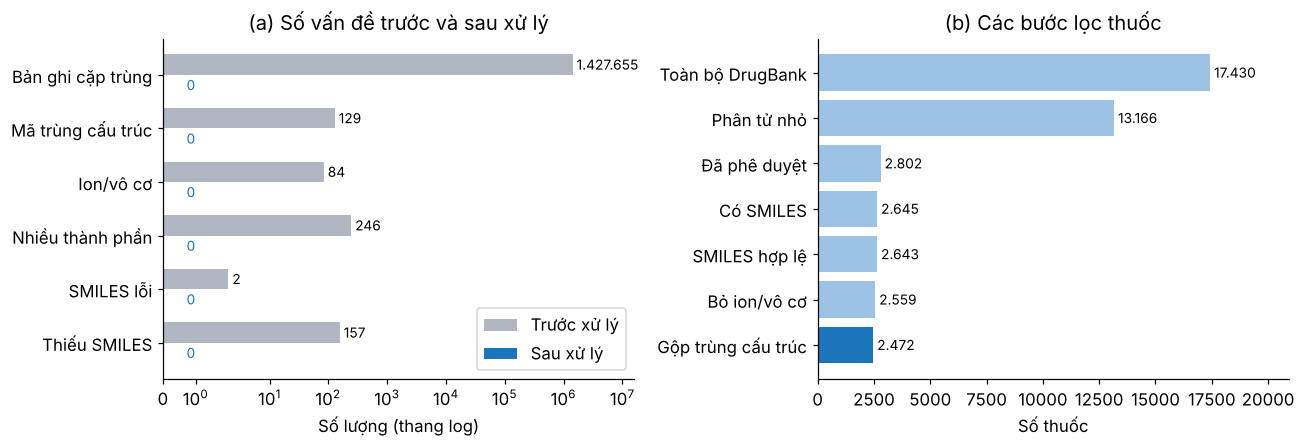

In [7]:
# So sánh trước – sau xử lý
before_after = pd.DataFrame({
    "Trước xử lý": [int(drugs_raw[is_sm & is_appr].smiles.isna().sum()), len(invalid), int(multi.sum()),
                    int(tiny.sum()), int(std.shape[0] - n) if False else int(dup_mask.sum()), E - len(pairs_raw)],
    "Sau xử lý": [0, 0, int((clean.smiles_std.str.contains(r"\.", regex=True)).sum()), 0,
                  int(clean.smiles_std.duplicated().sum()), 0]},
    index=["Thiếu SMILES", "SMILES lỗi", "Nhiều thành phần", "Ion/vô cơ", "Mã trùng cấu trúc", "Bản ghi cặp trùng"])
display(before_after)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
y = np.arange(len(before_after)); w = 0.38
ax[0].barh(y + w/2, before_after["Trước xử lý"], w, color=GR, label="Trước xử lý")
ax[0].barh(y - w/2, before_after["Sau xử lý"], w, color=BLUE, label="Sau xử lý")
for i, (b_, a_) in enumerate(zip(before_after["Trước xử lý"], before_after["Sau xử lý"])):
    ax[0].text(max(b_, 1), i + w/2, " " + fmt(int(b_)), va="center", fontsize=9); ax[0].text(max(a_, 0.6), i - w/2, " " + fmt(int(a_)), va="center", fontsize=9, color=BLUE)
ax[0].set_yticks(y); ax[0].set_yticklabels(before_after.index); ax[0].set_xscale("symlog"); ax[0].set_xlabel("Số lượng (thang log)"); ax[0].margins(x=0.15)
ax[0].set_title("(a) Số vấn đề trước và sau xử lý"); ax[0].legend(loc="lower right")
ax[1].barh(funnel.index[::-1], funnel.values[::-1], color=[BLUE] + [LB] * (len(funnel) - 1))
for i, v in enumerate(funnel.values[::-1]): ax[1].text(v, i, " " + fmt(int(v)), va="center", fontsize=9)
ax[1].set_xlabel("Số thuốc"); ax[1].set_title("(b) Các bước lọc thuốc"); ax[1].margins(x=0.2)
plt.tight_layout(); savefig("fig01_truoc_sau_lam_sach.png")

## 4. Tạo tập mẫu cặp thuốc (mẫu dương / mẫu âm)

In [8]:
N_POS = 50_000          # số cặp dương lấy mẫu (≈ 8,5% số cặp tương tác sau làm sạch)
NEG_RATIO = 1           # mẫu âm : mẫu dương
from sklearn.metrics import roc_auc_score

deg = pd.concat([pos.drug1, pos.drug2]).value_counts()          # bậc = số thuốc tương tác (trong phạm vi đã làm sạch)
deg_all = pd.Series(0, index=sorted(keep)).add(deg, fill_value=0).astype(int)
known_all = set(zip(pairs_raw.drug1, pairs_raw.drug2)) | set(zip(p.d1, p.d2))   # mọi cặp đã biết

def sample_negatives(pool, n, seed):
    r = np.random.default_rng(seed); pool = np.array(sorted(pool)); out, seen = [], set()
    while len(out) < n:
        a, b = r.choice(pool, 2, replace=False); pr = (a, b) if a < b else (b, a)
        if pr in known_all or pr in seen: continue
        seen.add(pr); out.append(pr)
    return pd.DataFrame(out, columns=["drug1", "drug2"])

pos_s = pos.iloc[rng.choice(len(pos), N_POS, replace=False)].reset_index(drop=True)
# Phương án 1: ghép ngẫu nhiên trong TOÀN BỘ thuốc đã làm sạch
neg_v1 = sample_negatives(keep, N_POS * NEG_RATIO, SEED)
# Phương án 2 (chọn): chỉ ghép trong các thuốc có ≥ 1 tương tác đã biết – giống Ran et al. (2022)
pool2 = set(deg_all[deg_all > 0].index)
neg_v2 = sample_negatives(pool2, N_POS * NEG_RATIO, SEED)

def bias_report(neg, name):
    dm_pos = np.minimum(deg_all[pos_s.drug1].values, deg_all[pos_s.drug2].values)
    dm_neg = np.minimum(deg_all[neg.drug1].values, deg_all[neg.drug2].values)
    y = np.r_[np.ones(len(dm_pos)), np.zeros(len(dm_neg))]
    return {"Phương án": name, "Số thuốc dùng để ghép": int(len(set(neg.drug1) | set(neg.drug2) | set(pos_s.drug1) | set(pos_s.drug2))),
            "% mẫu âm chứa thuốc bậc 0": round(100 * float((dm_neg == 0).mean()), 1),
            "AUC đơn biến của 'bậc nhỏ hơn'": round(roc_auc_score(y, np.r_[dm_pos, dm_neg]), 3)}
neg_cmp = pd.DataFrame([bias_report(neg_v1, "1: ghép trong toàn bộ 2.472 thuốc"), bias_report(neg_v2, f"2: ghép trong {len(pool2)} thuốc có ≥ 1 tương tác")])
display(neg_cmp)
STATS.update(n_drugs_degree0=int((deg_all == 0).sum()), n_pool_neg=len(pool2), neg_sampling_compare=neg_cmp.to_dict(orient="records"))

data = pd.concat([pos_s.assign(label=1), neg_v2.assign(label=0)], ignore_index=True)
data = data.sample(frac=1, random_state=SEED).reset_index(drop=True)
STATS.update(n_pos_sample=int(data.label.sum()), n_neg_sample=int((data.label == 0).sum()), n_samples=len(data))
print(data.label.value_counts()); data.head()

,Phương án,Số thuốc dùng để ghép,% mẫu âm chứa thuốc bậc 0,AUC đơn biến của 'bậc nhỏ hơn'
0,1: ghép trong toàn bộ 2.472 thuốc,2472,37.9,0.909
1,2: ghép trong 2058 thuốc có ≥ 1 tương tác,2058,0.0,0.854


label
0    50000
1    50000
Name: count, dtype: int64


,drug1,drug2,label
0,DB05812,DB13274,0
1,DB00494,DB01319,0
2,DB00201,DB06770,1
3,DB00650,DB02925,0
4,DB00541,DB11127,0


## 5. Thống kê mô tả và phân bố

In [9]:
def descriptors(smi):
    m = Chem.MolFromSmiles(smi)
    return {"mol_wt": Descriptors.MolWt(m), "logp": Crippen.MolLogP(m), "tpsa": rdMolDescriptors.CalcTPSA(m),
            "hbd": rdMolDescriptors.CalcNumHBD(m), "hba": rdMolDescriptors.CalcNumHBA(m),
            "rot_bonds": rdMolDescriptors.CalcNumRotatableBonds(m), "rings": rdMolDescriptors.CalcNumRings(m),
            "arom_rings": rdMolDescriptors.CalcNumAromaticRings(m), "heavy_atoms": m.GetNumHeavyAtoms()}
desc = pd.DataFrame([descriptors(s) for s in clean.smiles_std])
clean = pd.concat([clean[["drugbank_id", "name", "groups", "smiles_raw", "smiles_std"]], desc], axis=1)
clean["degree"] = clean.drugbank_id.map(deg_all).fillna(0).astype(int)
DESC = ["mol_wt", "logp", "tpsa", "hbd", "hba", "rot_bonds", "rings", "arom_rings", "heavy_atoms", "degree"]
desc_stats = clean[DESC].describe().T.round(2)
desc_stats["skew"] = clean[DESC].skew().round(2)
display(desc_stats)
clean.to_csv(f"{PROC}/drugs_clean.csv", index=False)

,count,mean,std,min,25%,50%,75%,max,skew
mol_wt,2472.0,388.70,283.50,40.02,248.32,337.46,445.79,4610.27,5.48
logp,2472.0,2.22,2.99,-23.83,0.72,2.53,3.95,18.47,-0.93
tpsa,2472.0,95.96,107.99,0.00,44.28,74.71,111.01,1690.64,6.32
hbd,2472.0,2.33,3.58,0.00,1.00,2.00,3.00,57.00,6.34
hba,2472.0,5.28,4.92,0.00,3.00,4.00,6.00,88.00,5.42
rot_bonds,2472.0,6.07,8.09,0.00,2.00,4.00,7.00,149.00,7.78
rings,2472.0,2.87,5.63,0.00,1.00,3.00,4.00,264.00,40.57
arom_rings,2472.0,1.50,1.36,0.00,0.00,1.00,2.00,22.00,2.15
heavy_atoms,2472.0,26.66,19.53,3.00,17.00,23.00,31.00,295.00,5.39
degree,2472.0,477.99,396.02,0.00,50.75,494.50,792.00,1619.00,0.31


In [10]:
# Ngoại lai (quy tắc IQR) trên các mô tả của thuốc
out = {}
for c in DESC:
    q1, q3 = clean[c].quantile([0.25, 0.75]); iqr = q3 - q1
    out[c] = int(((clean[c] < q1 - 1.5 * iqr) | (clean[c] > q3 + 1.5 * iqr)).sum())
outliers = pd.Series(out, name="Số ngoại lai (IQR)").to_frame(); outliers["Tỷ lệ (%)"] = (100 * outliers.iloc[:, 0] / len(clean)).round(1)
display(outliers)
STATS["outliers_iqr"] = out
print("5 thuốc nặng nhất:"); display(clean.nlargest(5, "mol_wt")[["drugbank_id", "name", "mol_wt", "heavy_atoms"]])

,Số ngoại lai (IQR),Tỷ lệ (%)
mol_wt,154,6.2
logp,100,4.0
tpsa,135,5.5
hbd,129,5.2
hba,209,8.5
rot_bonds,141,5.7
rings,26,1.1
arom_rings,23,0.9
heavy_atoms,133,5.4
degree,0,0.0


5 thuốc nặng nhất:


,drugbank_id,name,mol_wt,heavy_atoms
2348,DB14909,Imetelstat,4610.272,295
2204,DB13928,Semaglutide,4113.641,291
1071,DB01278,Pramlintide,3949.455,277
2396,DB15636,Zilucoplan,3562.229,251
1075,DB01284,Tetracosactide,2933.492,208


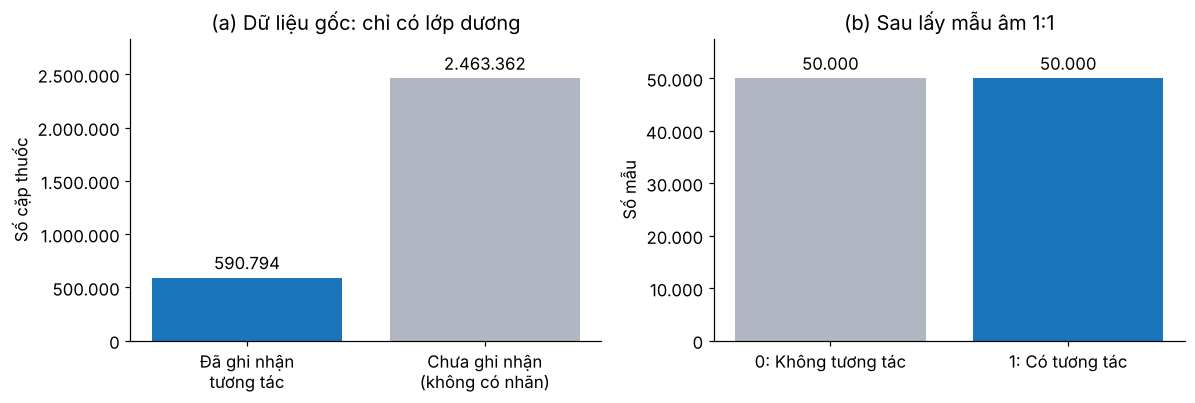

In [11]:
# Hình 2: phân bố nhãn
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
v = [STATS["n_pos_clean"], STATS["n_possible_pairs"] - STATS["n_pos_clean"]]
b = ax[0].bar(["Đã ghi nhận\ntương tác", "Chưa ghi nhận\n(không có nhãn)"], v, color=[BLUE, GR])
from matplotlib.ticker import FuncFormatter
ax[0].yaxis.set_major_formatter(FuncFormatter(lambda x, _: fmt(int(x)))); ax[1].yaxis.set_major_formatter(FuncFormatter(lambda x, _: fmt(int(x))))
ax[0].bar_label(b, labels=[fmt(x) for x in v], padding=3); ax[0].set_ylabel("Số cặp thuốc"); ax[0].set_title("(a) Dữ liệu gốc: chỉ có lớp dương")
ax[0].margins(y=0.15)
vc = data.label.value_counts().sort_index()
b = ax[1].bar(["0: Không tương tác", "1: Có tương tác"], vc.values, color=[GR, BLUE])
ax[1].bar_label(b, labels=[fmt(x) for x in vc.values], padding=3); ax[1].set_ylabel("Số mẫu"); ax[1].set_title("(b) Sau lấy mẫu âm 1:1"); ax[1].margins(y=0.15)
plt.tight_layout(); savefig("fig02_phan_bo_nhan.png")

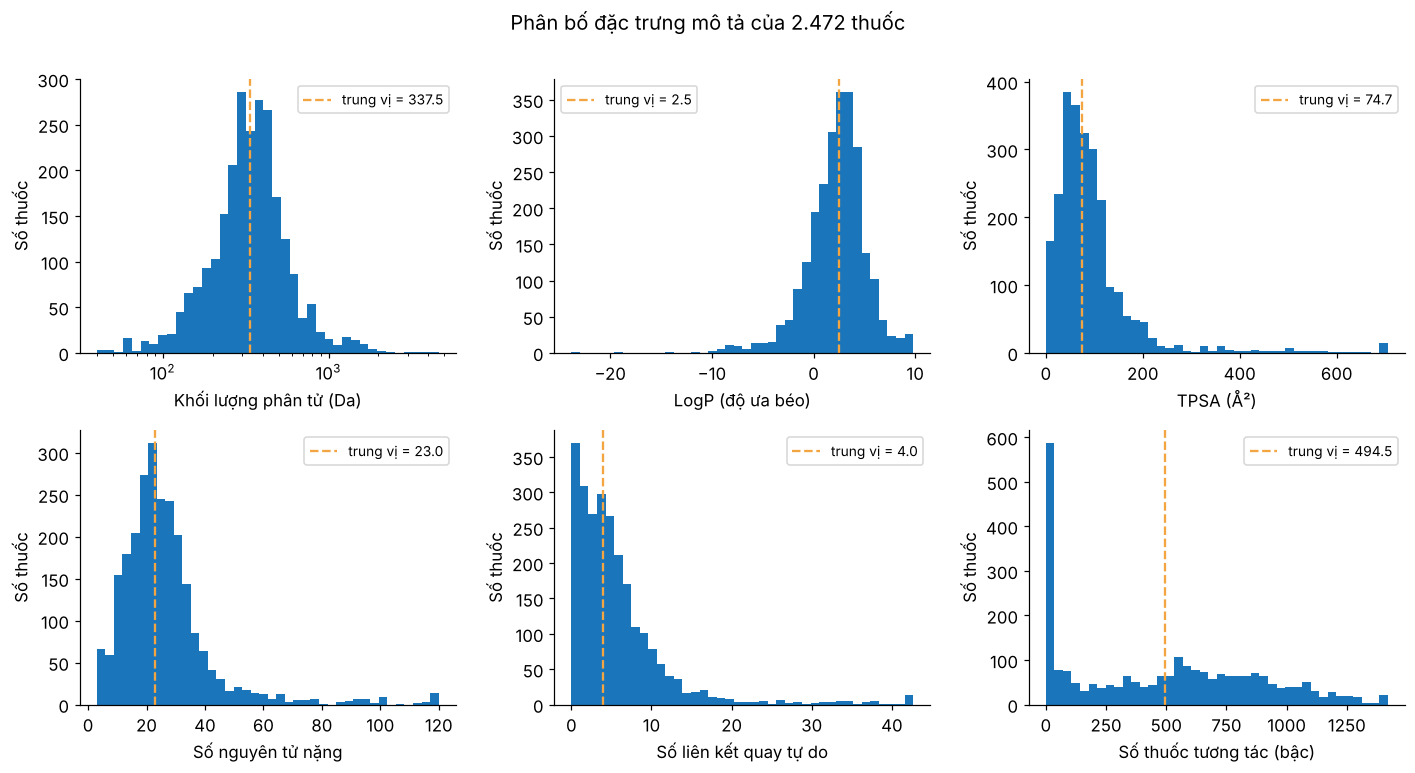

In [12]:
# Hình 3: phân bố các đặc trưng mô tả chính của thuốc
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
spec = [("mol_wt", "Khối lượng phân tử (Da)", True), ("logp", "LogP (độ ưa béo)", False), ("tpsa", "TPSA (Å²)", False),
        ("heavy_atoms", "Số nguyên tử nặng", False), ("rot_bonds", "Số liên kết quay tự do", False), ("degree", "Số thuốc tương tác (bậc)", False)]
for ax, (c, lab, logx) in zip(axes.flat, spec):
    x = clean[c]
    if logx: ax.hist(x, bins=np.logspace(np.log10(max(x.min(), 10)), np.log10(x.max()), 40), color=BLUE); ax.set_xscale("log")
    else: ax.hist(x.clip(upper=x.quantile(0.995)), bins=40, color=BLUE)
    ax.axvline(x.median(), color=OR, ls="--", lw=1.5, label=f"trung vị = {x.median():.1f}")
    ax.set_xlabel(lab); ax.set_ylabel("Số thuốc"); ax.legend(fontsize=9)
plt.suptitle(f"Phân bố đặc trưng mô tả của {fmt(len(clean))} thuốc", y=1.0); plt.tight_layout(); savefig("fig03_phan_bo_mo_ta.png")

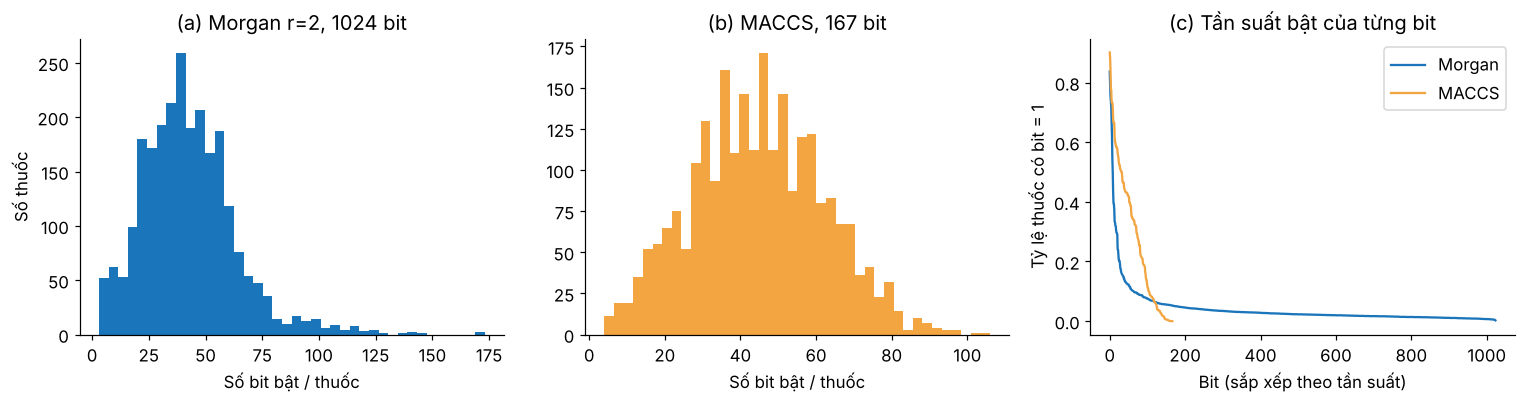

{
 "morgan_on_median": 40.0,
 "maccs_on_median": 44.0,
 "morgan_bits_never": 0,
 "maccs_bits_never": 6,
 "morgan_density": 0.0415,
 "maccs_density": 0.2678
}


In [13]:
# Đặc trưng đưa vào mô hình: fingerprint của từng thuốc
mgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
MORGAN, MACCS, FPOBJ = {}, {}, {}
for r in clean.itertuples():
    m = Chem.MolFromSmiles(r.smiles_std)
    FPOBJ[r.drugbank_id] = mgen.GetFingerprint(m)
    MORGAN[r.drugbank_id] = mgen.GetFingerprintAsNumPy(m).astype(np.uint8)
    v = np.zeros(167, np.uint8); v[list(MACCSkeys.GenMACCSKeys(m).GetOnBits())] = 1; MACCS[r.drugbank_id] = v
M = np.stack([MORGAN[i] for i in clean.drugbank_id]); K = np.stack([MACCS[i] for i in clean.drugbank_id])
STATS.update(morgan_on_median=float(np.median(M.sum(1))), maccs_on_median=float(np.median(K.sum(1))),
             morgan_bits_never=int((M.sum(0) == 0).sum()), maccs_bits_never=int((K.sum(0) == 0).sum()),
             morgan_density=round(float(M.mean()), 4), maccs_density=round(float(K.mean()), 4))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(M.sum(1), bins=40, color=BLUE); ax[0].set_xlabel("Số bit bật / thuốc"); ax[0].set_ylabel("Số thuốc"); ax[0].set_title("(a) Morgan r=2, 1024 bit")
ax[1].hist(K.sum(1), bins=40, color=OR); ax[1].set_xlabel("Số bit bật / thuốc"); ax[1].set_title("(b) MACCS, 167 bit")
ax[2].plot(np.sort(M.mean(0))[::-1], color=BLUE, label="Morgan"); ax[2].plot(np.sort(K.mean(0))[::-1], color=OR, label="MACCS")
ax[2].set_xlabel("Bit (sắp xếp theo tần suất)"); ax[2].set_ylabel("Tỷ lệ thuốc có bit = 1"); ax[2].set_title("(c) Tần suất bật của từng bit"); ax[2].legend()
plt.tight_layout(); savefig("fig04_fingerprint.png")
print(json.dumps({k: STATS[k] for k in ["morgan_on_median", "maccs_on_median", "morgan_bits_never", "maccs_bits_never", "morgan_density", "maccs_density"]}, indent=1))

## 6. Quan hệ giữa các đặc trưng và với nhãn

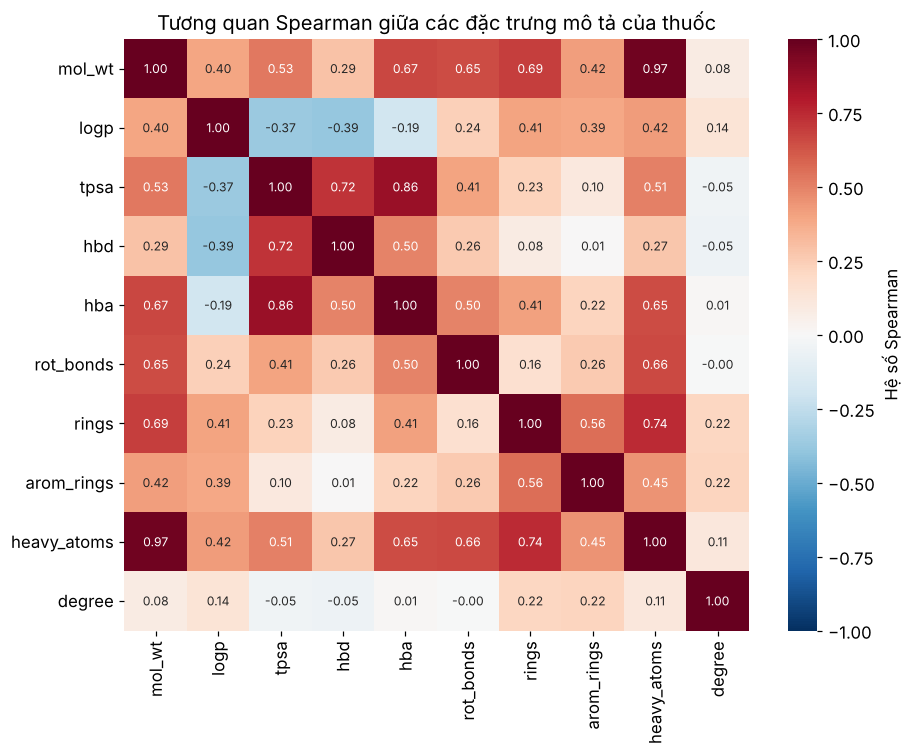

Cặp tương quan mạnh (|r| ≥ 0,8): [('mol_wt', 'heavy_atoms', np.float64(0.97)), ('tpsa', 'hba', np.float64(0.86))]


In [14]:
# Hình 5: tương quan giữa các mô tả của thuốc (Spearman vì nhiều biến lệch)
corr = clean[DESC].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Hệ số Spearman"},
            xticklabels=DESC, yticklabels=DESC, annot_kws={"size": 8})
ax.set_title("Tương quan Spearman giữa các đặc trưng mô tả của thuốc"); plt.tight_layout(); savefig("fig05_tuong_quan.png")
hi = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(DESC) for b in DESC[i+1:] if abs(corr.loc[a, b]) >= 0.8]
print("Cặp tương quan mạnh (|r| ≥ 0,8):", hi); STATS["high_corr"] = hi

In [15]:
# Đặc trưng ở mức cặp thuốc (chỉ để khảo sát quan hệ với nhãn, không đưa trực tiếp vào mô hình)
cl = clean.set_index("drugbank_id")
d1, d2 = data.drug1.values, data.drug2.values
pair = pd.DataFrame({
    "tanimoto": [DataStructs.TanimotoSimilarity(FPOBJ[a], FPOBJ[b]) for a, b in zip(d1, d2)],
    "deg_min": np.minimum(cl.loc[d1, "degree"].values, cl.loc[d2, "degree"].values),
    "deg_sum": cl.loc[d1, "degree"].values + cl.loc[d2, "degree"].values,
    "mw_sum": cl.loc[d1, "mol_wt"].values + cl.loc[d2, "mol_wt"].values,
    "logp_absdiff": np.abs(cl.loc[d1, "logp"].values - cl.loc[d2, "logp"].values),
    "tpsa_sum": cl.loc[d1, "tpsa"].values + cl.loc[d2, "tpsa"].values,
    "label": data.label.values})
uni = pd.DataFrame({c: {"TB lớp 1": pair.loc[pair.label == 1, c].mean(), "TB lớp 0": pair.loc[pair.label == 0, c].mean(),
                         "AUC đơn biến": roc_auc_score(pair.label, pair[c])} for c in pair.columns[:-1]}).T.round(3)
display(uni); STATS["univariate"] = uni.to_dict(orient="index")

,TB lớp 1,TB lớp 0,AUC đơn biến
tanimoto,0.111,0.099,0.570
deg_min,631.078,260.572,0.854
deg_sum,1612.998,965.584,0.858
mw_sum,761.619,801.671,0.481
logp_absdiff,2.424,3.158,0.419
tpsa_sum,172.777,201.334,0.436


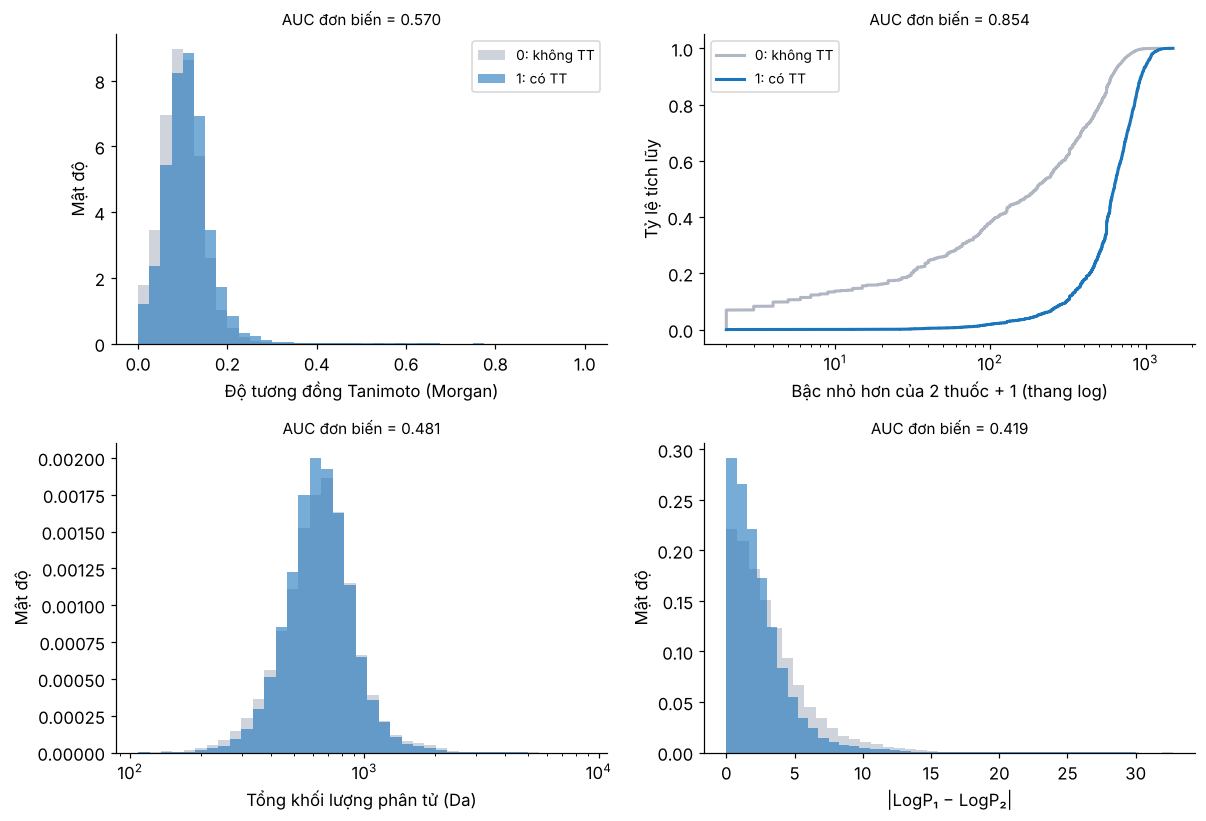

In [16]:
# Hình 6: phân bố đặc trưng cặp theo nhãn
fig, axes = plt.subplots(2, 2, figsize=(11, 7.6)); axes = axes.ravel()
pair["deg_min_p1"] = pair["deg_min"] + 1
spec = [("tanimoto", "Độ tương đồng Tanimoto (Morgan)", False), ("deg_min_p1", "Bậc nhỏ hơn của 2 thuốc + 1 (thang log)", True),
        ("mw_sum", "Tổng khối lượng phân tử (Da)", True), ("logp_absdiff", "|LogP₁ − LogP₂|", False)]
for ax, (c, lab, logx) in zip(axes, spec):
    if c == "deg_min_p1":   # phân bố lệch mạnh -> dùng hàm phân phối tích lũy (ECDF)
        for lv, col, name in [(0, GR, "0: không TT"), (1, BLUE, "1: có TT")]:
            x = np.sort(pair.loc[pair.label == lv, c].values); ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=col, lw=2, label=name)
        ax.set_xscale("log"); ax.set_xlabel(lab); ax.set_ylabel("Tỷ lệ tích lũy"); ax.legend(fontsize=9)
        ax.set_title(f"AUC đơn biến = {uni.loc['deg_min', 'AUC đơn biến']:.3f}", fontsize=10); continue
    for lv, col, name in [(0, GR, "0: không TT"), (1, BLUE, "1: có TT")]:
        x = pair.loc[pair.label == lv, c]
        bins = np.logspace(np.log10(max(pair[c].min(), 1)), np.log10(pair[c].max()), 40) if logx else 40
        ax.hist(x, bins=bins, alpha=0.6, color=col, label=name, density=True)
    if logx: ax.set_xscale("log")
    ax.set_xlabel(lab); ax.set_ylabel("Mật độ"); ax.set_title(f"AUC đơn biến = {uni.loc[c.replace('_p1', ''), 'AUC đơn biến']:.3f}", fontsize=10)
axes[0].legend(fontsize=9); plt.tight_layout(); savefig("fig06_dac_trung_cap_theo_nhan.png")

,key,MI,SMARTS,TL lớp 1 (có ≥1),TL lớp 0 (có ≥1)
161,162,0.0096,a,0.9649,0.9370
162,163,0.0077,*1~*~*~*~*~*~1,0.9911,0.9825
138,139,0.0064,[O;!H0],0.7034,0.7945
144,145,0.0063,*1~*~*~*~*~*~1 (>1 lần),0.8909,0.8616
164,165,0.0063,[R],0.9962,0.9916
157,158,0.0061,[#6]-[#7],0.9615,0.9432
124,125,0.0060,> 1 vòng thơm,0.7865,0.7293
160,161,0.0058,[#7],0.9736,0.9606
143,144,0.0049,*!:*:*!:*,0.7719,0.7062
155,156,0.0046,[#7]~*(~*)~*,0.9414,0.9131


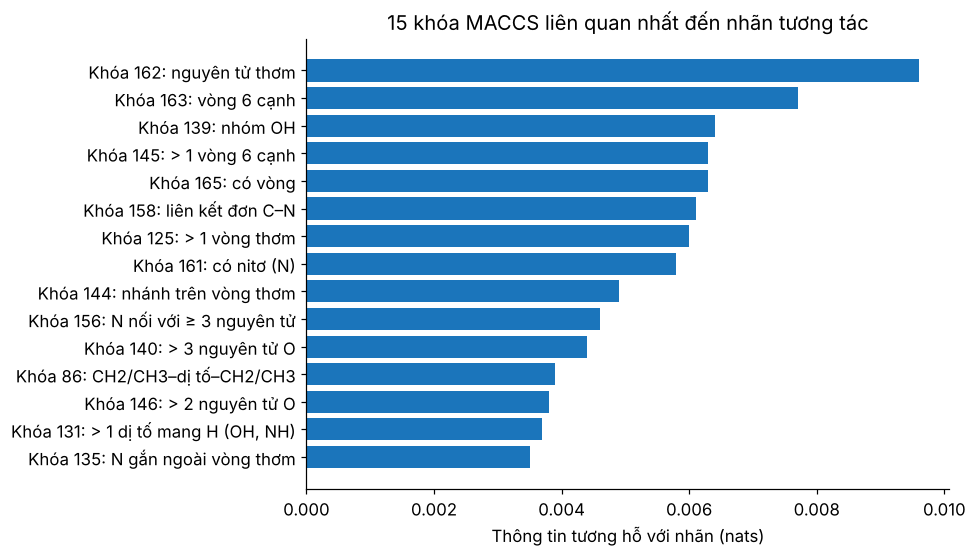

Số cặp khóa MACCS |r| > 0,9: 22


In [17]:
# Hình 7: thông tin tương hỗ (mutual information) giữa từng khóa MACCS và nhãn
# Với mỗi khóa k, đếm số thuốc trong cặp có khóa đó (0, 1 hoặc 2)
from sklearn.feature_selection import mutual_info_classif
KA = np.stack([MACCS[a] for a in d1]).astype(np.int8); KB = np.stack([MACCS[b] for b in d2]).astype(np.int8)
cnt = KA + KB
mi = mutual_info_classif(cnt[:, 1:], data.label.values, discrete_features=True, random_state=SEED)
smarts = {k: (v[0] + (f" (>{v[1]} lần)" if v[1] > 0 else "")) for k, v in MACCSkeys.smartsPatts.items()}
smarts.update({1: "đồng vị", 125: "> 1 vòng thơm", 166: "nhiều mảnh phân tử"})
VI = {163: "vòng 6 cạnh", 145: "> 1 vòng 6 cạnh", 165: "có vòng", 162: "nguyên tử thơm", 158: "liên kết đơn C–N", 161: "có nitơ (N)",
      121: "N nằm trong vòng", 156: "N nối với ≥ 3 nguyên tử", 137: "dị nguyên tử trong vòng", 125: "> 1 vòng thơm", 144: "nhánh trên vòng thơm",
      111: "N–X–CH2–X", 142: "> 1 nguyên tử N", 100: "CH2 nối với N", 122: "N nối 3 nhánh", 164: "có oxy (O)", 160: "nhóm CH3", 159: "> 1 nguyên tử O",
      157: "liên kết đơn C–O", 154: "liên kết đôi C=O", 139: "nhóm OH", 143: "O nối ngoài vòng", 152: "O–C(–C)–C", 146: "> 2 nguyên tử O", 149: "> 1 nhóm CH3",
      140: "> 3 nguyên tử O", 86: "CH2/CH3–dị tố–CH2/CH3", 131: "> 1 dị tố mang H (OH, NH)", 135: "N gắn ngoài vòng thơm"}
mi_df = pd.DataFrame({"key": np.arange(1, 167), "MI": mi, "SMARTS": [smarts.get(k, "?") for k in range(1, 167)],
                      "TL lớp 1 (có ≥1)": (cnt[data.label.values == 1, 1:] > 0).mean(0), "TL lớp 0 (có ≥1)": (cnt[data.label.values == 0, 1:] > 0).mean(0)})
top = mi_df.nlargest(15, "MI").round(4); display(top)
STATS["maccs_top_mi"] = top[["key", "MI", "SMARTS", "TL lớp 1 (có ≥1)", "TL lớp 0 (có ≥1)"]].assign(desc=[VI.get(k, "") for k in top.key]).to_dict(orient="records")
fig, ax = plt.subplots(figsize=(9, 5.2))
lab = [f"Khóa {k}: {VI.get(k, s[:24])}" for k, s in zip(top.key, top.SMARTS)]
top["Mô tả"] = [VI.get(k, "") for k in top.key]
ax.barh(lab[::-1], top.MI.values[::-1], color=BLUE); ax.set_xlabel("Thông tin tương hỗ với nhãn (nats)")
ax.set_title("15 khóa MACCS liên quan nhất đến nhãn tương tác"); plt.tight_layout(); savefig("fig07_maccs_mi.png")
# Độ dư thừa: số cặp khóa MACCS tương quan rất mạnh
kc = np.corrcoef(K[:, K.std(0) > 0].T); iu = np.triu_indices_from(kc, 1)
STATS["maccs_pairs_corr_gt09"] = int((np.abs(kc[iu]) > 0.9).sum()); print("Số cặp khóa MACCS |r| > 0,9:", STATS["maccs_pairs_corr_gt09"])

## 7. Chuẩn bị dữ liệu cho mô hình

In [18]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold

def build_features(df):
    """Vector cặp = [Morgan(A) ‖ MACCS(A) ‖ Morgan(B) ‖ MACCS(B)] – 2 × (1024 + 167) = 2382 chiều, kiểu uint8."""
    A = np.hstack([np.stack([MORGAN[i] for i in df.drug1]), np.stack([MACCS[i] for i in df.drug1])])
    B = np.hstack([np.stack([MORGAN[i] for i in df.drug2]), np.stack([MACCS[i] for i in df.drug2])])
    return np.hstack([A, B])
FEATURE_NAMES = [f"A_morgan_{i}" for i in range(1024)] + [f"A_maccs_{i}" for i in range(167)] + \
                [f"B_morgan_{i}" for i in range(1024)] + [f"B_maccs_{i}" for i in range(167)]

# (1) Chia hold-out phân tầng 80/20 – tập kiểm tra giữ lại đến cuối
idx_tr, idx_te = train_test_split(np.arange(len(data)), test_size=0.2, stratify=data.label, random_state=SEED)
data["split"] = "train"; data.loc[idx_te, "split"] = "test"
X_train, X_test = build_features(data.iloc[idx_tr]), build_features(data.iloc[idx_te])
y_train, y_test = data.label.values[idx_tr], data.label.values[idx_te]

# (2) Lọc đặc trưng hằng số và chuẩn hóa – CHỈ fit trên tập huấn luyện
vt = VarianceThreshold(0.0).fit(X_train)
scaler = StandardScaler().fit(vt.transform(X_train).astype(np.float32))
Xtr_s = scaler.transform(vt.transform(X_train).astype(np.float32)); Xte_s = scaler.transform(vt.transform(X_test).astype(np.float32))
print(f"Đặc trưng hằng số trên tập train: {X_train.shape[1] - vt.get_support().sum()} / {X_train.shape[1]}")
print(f"Sau chuẩn hóa – train: mean={Xtr_s.mean():.3f}, std={Xtr_s.std():.3f} | test: mean={Xte_s.mean():.3f}, std={Xte_s.std():.3f}")

# (3) Kịch bản chia theo nhóm thuốc (thuốc mới) – dùng ở giai đoạn cải tiến/tổng quát hóa
drug_list = np.array(sorted(set(data.drug1) | set(data.drug2))); new = set(np.random.default_rng(SEED).choice(drug_list, int(0.2 * len(drug_list)), replace=False))
cat = data.drug1.isin(new).astype(int) + data.drug2.isin(new).astype(int)
data["cold_group"] = cat.map({0: "train_known", 1: "S1_one_new", 2: "S2_two_new"})

split_tab = pd.DataFrame({
    "Số mẫu": [len(idx_tr), len(idx_te)] + [int((data.cold_group == g).sum()) for g in ["train_known", "S1_one_new", "S2_two_new"]],
    "Số đặc trưng": [X_train.shape[1]] * 5,
    "Tỷ lệ lớp dương": [y_train.mean(), y_test.mean()] + [data.loc[data.cold_group == g, "label"].mean() for g in ["train_known", "S1_one_new", "S2_two_new"]]},
    index=["Hold-out: huấn luyện", "Hold-out: kiểm tra", "Theo thuốc: huấn luyện (2 thuốc đã biết)", "Theo thuốc: S1 (1 thuốc mới)", "Theo thuốc: S2 (2 thuốc mới)"]).round(3)
display(split_tab)
STATS.update(n_features=int(X_train.shape[1]), n_constant_train=int(X_train.shape[1] - vt.get_support().sum()),
             split=split_tab.reset_index().rename(columns={"index": "Tập"}).to_dict(orient="records"))
# Rò rỉ: số thuốc của tập kiểm tra đã xuất hiện trong tập huấn luyện (chia theo cặp)
tr_drugs = set(data.iloc[idx_tr].drug1) | set(data.iloc[idx_tr].drug2); te_drugs = set(data.iloc[idx_te].drug1) | set(data.iloc[idx_te].drug2)
STATS["test_drugs_seen_in_train_pct"] = round(100 * len(te_drugs & tr_drugs) / len(te_drugs), 1)
print(f"Thuốc trong tập kiểm tra đã xuất hiện ở tập huấn luyện: {STATS['test_drugs_seen_in_train_pct']}%")

Đặc trưng hằng số trên tập train: 16 / 2382


Sau chuẩn hóa – train: mean=-0.000, std=1.000 | test: mean=0.000, std=1.002


,Số mẫu,Số đặc trưng,Tỷ lệ lớp dương
Hold-out: huấn luyện,80000,2382,0.500
Hold-out: kiểm tra,20000,2382,0.500
Theo thuốc: huấn luyện (2 thuốc đã biết),63756,2382,0.495
Theo thuốc: S1 (1 thuốc mới),32208,2382,0.508
Theo thuốc: S2 (2 thuốc mới),4036,2382,0.513


Thuốc trong tập kiểm tra đã xuất hiện ở tập huấn luyện: 100.0%


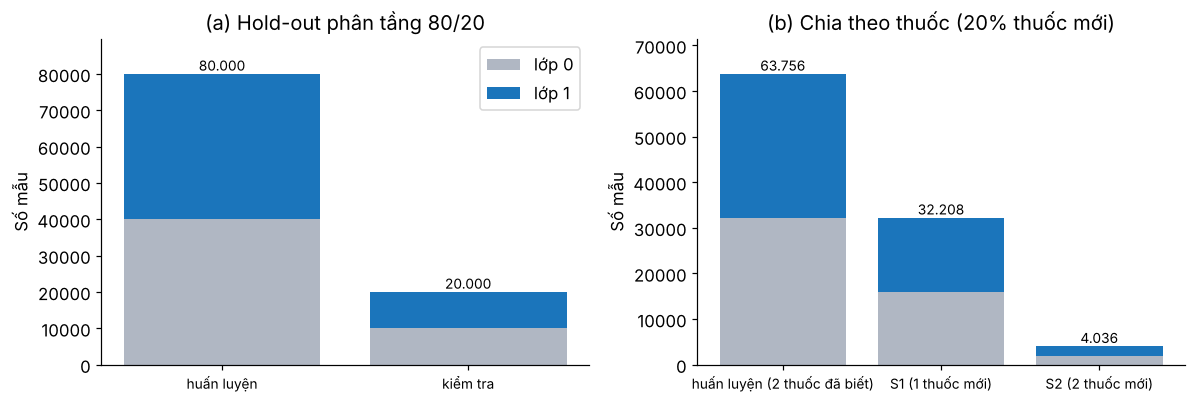

Đã lưu: data/processed/drugs_clean.csv, dataset_pairs.csv.gz, data_quality_issues.csv, eda_stats.json


In [19]:
# Hình 8: kích thước các tập
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, rows_, title in [(ax[0], split_tab.index[:2], "(a) Hold-out phân tầng 80/20"), (ax[1], split_tab.index[2:], "(b) Chia theo thuốc (20% thuốc mới)")]:
    sub = split_tab.loc[rows_]
    lbl = [r.split(": ")[1] for r in sub.index]
    pos_ = (sub["Số mẫu"] * sub["Tỷ lệ lớp dương"]).values; neg_ = sub["Số mẫu"].values - pos_
    a.bar(lbl, neg_, color=GR, label="lớp 0"); a.bar(lbl, pos_, bottom=neg_, color=BLUE, label="lớp 1")
    for i, t in enumerate(sub["Số mẫu"].values): a.text(i, t, fmt(int(t)), ha="center", va="bottom", fontsize=9)
    a.set_ylabel("Số mẫu"); a.set_title(title); a.tick_params(axis="x", labelsize=9); a.margins(y=0.12)
ax[0].legend(); plt.tight_layout(); savefig("fig08_chia_tap.png")

data[["drug1", "drug2", "label", "split", "cold_group"]].to_csv(f"{PROC}/dataset_pairs.csv.gz", index=False)
issues_df.to_csv(f"{PROC}/data_quality_issues.csv", index=False)
STATS["issues"] = issues_df.to_dict(orient="records")
json.dump(STATS, open(f"{PROC}/eda_stats.json", "w"), ensure_ascii=False, indent=1, default=str)
print("Đã lưu: data/processed/drugs_clean.csv, dataset_pairs.csv.gz, data_quality_issues.csv, eda_stats.json")